# Case Study: Census

In [1]:
# datascience
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')


In [2]:
# polars
import polars as pl
from IPython.display import display
import hvplot.polars


## U.S. National Park Service

Source: [Responsible Datasets in Context](https://www.responsible-datasets-in-context.com/posts/np-data/)

<img src="https://www.nps.gov/common/uploads/structured_data/3C84CF74-1DD8-B71B-0B9C7FF83F7C68EB.jpg?width=990&height=742&mode=crop&quality=78" alt="photo of mountains and trees in Yosemite National Park" width="400 px" />

In [3]:
# datascience
# load in data
# recreational visits to U.S. national parks in 2024
nps = Table.read_table('US-National-Parks_RecreationVisits_1979-2024.csv')
nps = nps.where("Year", 2024).drop("Year", "Region").sort("Visits", 2024)
nps.show(3)


Park,Park Code,State,Visits
Great Smoky Mountains NP,GRSM,TN,12191834
Zion NP,ZION,UT,4946592
Grand Canyon NP,GRCA,AZ,4919163


In [4]:
# polars
# load in data
# recreational visits to U.S. national parks in 2024
nps_pl = pl.read_csv('US-National-Parks_RecreationVisits_1979-2024.csv')
nps_pl = nps_pl.filter((pl.col("Year") == (2024))).drop("Year", "Region").sort("Visits", descending=True)
nps_pl.head(3)


Park,Park Code,State,Visits
str,str,str,i64
"""Great Smoky Mountains NP""","""GRSM""","""TN""",12191834
"""Zion NP""","""ZION""","""UT""",4946592
"""Grand Canyon NP""","""GRCA""","""AZ""",4919163


In [5]:
# datascience
# `take`
# 1. what is the tenth most visited park?
# 2. how do I see just that row?
# 3. how do I see the row after that?

nps.take(9, 10)


Park,Park Code,State,Visits
Glacier NP,GLAC,MT,3208755
Joshua Tree NP,JOTR,CA,2991874


In [6]:
# polars
# `take`
# 1. what is the tenth most visited park?
# 2. how do I see just that row?
# 3. how do I see the row after that?

nps_pl.gather(9)


Park,Park Code,State,Visits
str,str,str,i64
"""Glacier NP""","""GLAC""","""MT""",3208755


In [7]:
# datascience
# more common: we will use `where` to pick out rows based on some condition
nps.where('State', 'CA').show(2)


Park,Park Code,State,Visits
Yosemite NP,YOSE,CA,4121807
Joshua Tree NP,JOTR,CA,2991874


In [8]:
# polars
# more common: we will use `where` to pick out rows based on some condition
nps_pl.filter((pl.col('State') == ('CA'))).head(2)


Park,Park Code,State,Visits
str,str,str,i64
"""Yosemite NP""","""YOSE""","""CA""",4121807
"""Joshua Tree NP""","""JOTR""","""CA""",2991874


In [9]:
# datascience
# ... or equivalently
nps.where('State', are.equal_to('CA')).show(2)


Park,Park Code,State,Visits
Yosemite NP,YOSE,CA,4121807
Joshua Tree NP,JOTR,CA,2991874


In [10]:
# polars
# ... or equivalently
nps_pl.filter((pl.col('State') == ('CA'))).head(2)


Park,Park Code,State,Visits
str,str,str,i64
"""Yosemite NP""","""YOSE""","""CA""",4121807
"""Joshua Tree NP""","""JOTR""","""CA""",2991874


In [11]:
# datascience
# what about not equal to?
nps.where('State', are.not_equal_to('CA')).show(2)


Park,Park Code,State,Visits
Great Smoky Mountains NP,GRSM,TN,12191834
Zion NP,ZION,UT,4946592


In [12]:
# polars
# what about not equal to?
nps_pl.filter((pl.col('State') != ('CA'))).head(2)


Park,Park Code,State,Visits
str,str,str,i64
"""Great Smoky Mountains NP""","""GRSM""","""TN""",12191834
"""Zion NP""","""ZION""","""UT""",4946592


In [13]:
# datascience
# more common: conditions with numerical values
nps.where('Visits', are.between(1e5, 1e6)).show(2)


Park,Park Code,State,Visits
Saguaro NP,SAGU,AZ,946369
Canyonlands NP,CANY,UT,818492


In [14]:
# polars
# more common: conditions with numerical values
nps_pl.filter(pl.col('Visits').is_between(1e5, 1e6, closed='left')).head(2)


Park,Park Code,State,Visits
str,str,str,i64
"""Saguaro NP""","""SAGU""","""AZ""",946369
"""Canyonlands NP""","""CANY""","""UT""",818492


In [15]:
# datascience
# what fraction of parks satisfy the above condition?
nps.where('Visits', are.between(1e5, 1e6)).num_rows / nps.num_rows


0.4603174603174603

In [16]:
# polars
# what fraction of parks satisfy the above condition?
nps_pl.filter(pl.col('Visits').is_between(1e5, 1e6, closed='left')).height / nps_pl.height


0.4603174603174603

### Discussion Questions

The table `nps` has columns:


| Park | Park Code | State | Visits |
| :-- | :-- | :-- | :-- |
| ... | ... | ... | ... |


#### a) Create an **array** containing the names of all California parks that had more than 1 million visitors.

In [17]:
# ... code here ...


#### b) After evaluating these two expressions in order, what's the result of the second one?

In [18]:
# datascience
nps.drop('State')
nps.num_columns


4

In [19]:
# polars
nps_pl.drop('State')
nps_pl.width


4

<br/><br/><br/>

---

## Census ##

In [20]:
# datascience
full = Table.read_table('nc-est2025-agesex-res.csv')
full.show(5)


SEX,AGE,ESTIMATESBASE2020,POPESTIMATE2020,POPESTIMATE2021,POPESTIMATE2022,POPESTIMATE2023,POPESTIMATE2024,POPESTIMATE2025
0,0,3719470,3691723,3572165,3680529,3653453,3617221,3618898
0,1,3764281,3750601,3697247,3602579,3719819,3700305,3642657
0,2,3841150,3826776,3756935,3727216,3642279,3766783,3725891
0,3,3916585,3888055,3832978,3786311,3766965,3689270,3791993
0,4,3984785,3976772,3894042,3861295,3824021,3811156,3712428


In [21]:
# polars
full_pl = pl.read_csv('nc-est2025-agesex-res.csv')
full_pl.head(5)


SEX,AGE,ESTIMATESBASE2020,POPESTIMATE2020,POPESTIMATE2021,POPESTIMATE2022,POPESTIMATE2023,POPESTIMATE2024,POPESTIMATE2025
i64,i64,i64,i64,i64,i64,i64,i64,i64
0,0,3719470,3691723,3572165,3680529,3653453,3617221,3618898
0,1,3764281,3750601,3697247,3602579,3719819,3700305,3642657
0,2,3841150,3826776,3756935,3727216,3642279,3766783,3725891
0,3,3916585,3888055,3832978,3786311,3766965,3689270,3791993
0,4,3984785,3976772,3894042,3861295,3824021,3811156,3712428


In [22]:
# datascience
partial = full.select('SEX', 'AGE', 'POPESTIMATE2020', 'POPESTIMATE2025')
partial.show(6)


SEX,AGE,POPESTIMATE2020,POPESTIMATE2025
0,0,3691723,3618898
0,1,3750601,3642657
0,2,3826776,3725891
0,3,3888055,3791993
0,4,3976772,3712428
0,5,4005096,3833003


In [23]:
# polars
partial_pl = full_pl.select('SEX', 'AGE', 'POPESTIMATE2020', 'POPESTIMATE2025')
partial_pl.head(6)


SEX,AGE,POPESTIMATE2020,POPESTIMATE2025
i64,i64,i64,i64
0,0,3691723,3618898
0,1,3750601,3642657
0,2,3826776,3725891
0,3,3888055,3791993
0,4,3976772,3712428
0,5,4005096,3833003


### Newborns

**DISCUSS**: How can there be different values for newborn babies vs. five year olds five years later?

In [24]:
# datascience
partial.column(3).take(5) / partial.column(2).take(0)


1.0382693934512421

In [25]:
# polars
partial_pl.to_series(3).gather(5) / partial_pl.to_series(2).gather(0)


POPESTIMATE2025
f64
1.038269


In [26]:
# datascience
# make column labels a bit nicer
us_pop = partial.relabeled(2, '2020').relabeled(3, '2025')
us_pop.show(5)


SEX,AGE,2020,2025
0,0,3691723,3618898
0,1,3750601,3642657
0,2,3826776,3725891
0,3,3888055,3791993
0,4,3976772,3712428


In [27]:
# polars
# make column labels a bit nicer
us_pop_pl = partial_pl.rename({partial_pl.columns[2]: '2020'}).rename({partial_pl.rename({partial_pl.columns[2]: '2020'}).columns[3]: '2025'})
us_pop_pl.head(5)


SEX,AGE,2020,2025
i64,i64,i64,i64
0,0,3691723,3618898
0,1,3750601,3642657
0,2,3826776,3725891
0,3,3888055,3791993
0,4,3976772,3712428


### Elderly

In [28]:
# datascience
us_pop.where('AGE', are.above_or_equal_to(98)).sort('AGE').show()


SEX,AGE,2020,2025
0,98,71153,92407
1,98,17393,27452
2,98,53760,64955
0,99,50624,64325
1,99,12189,18663
2,99,38435,45662
0,100,79080,119182
1,100,16931,31539
2,100,62149,87643
0,999,331578104,341784857


In [29]:
# polars
with pl.Config(tbl_rows=-1):
    display(us_pop_pl.filter((pl.col('AGE') >= (98))).sort('AGE'))


SEX,AGE,2020,2025
i64,i64,i64,i64
0,98,71153,92407
1,98,17393,27452
2,98,53760,64955
0,99,50624,64325
1,99,12189,18663
2,99,38435,45662
0,100,79080,119182
1,100,16931,31539
2,100,62149,87643


In [30]:
# datascience
us_pop.where('SEX', 0).where('AGE', are.above_or_equal_to(98)).sort('AGE').show()


SEX,AGE,2020,2025
0,98,71153,92407
0,99,50624,64325
0,100,79080,119182
0,999,331578104,341784857


In [31]:
# polars
with pl.Config(tbl_rows=-1):
    display(us_pop_pl.filter((pl.col('SEX') == (0))).filter((pl.col('AGE') >= (98))).sort('AGE'))


SEX,AGE,2020,2025
i64,i64,i64,i64
0,98,71153,92407
0,99,50624,64325
0,100,79080,119182
0,999,331578104,341784857


In [32]:
# datascience
# how would we see the percent change by each age group?
percent_change = (us_pop.column('2025') - us_pop.column('2020')) / us_pop.column('2020')
us_pop_change = us_pop.with_column("Percent Change", percent_change).set_format("Percent Change", PercentFormatter)
us_pop_change.where('SEX', 0).where('AGE', are.above_or_equal_to(98)).sort('AGE').show()


SEX,AGE,2020,2025,Percent Change
0,98,71153,92407,29.87%
0,99,50624,64325,27.06%
0,100,79080,119182,50.71%
0,999,331578104,341784857,3.08%


In [33]:
# polars
# how would we see the percent change by each age group?
percent_change_pl = (us_pop_pl.get_column('2025') - us_pop_pl.get_column('2020')) / us_pop_pl.get_column('2020')
us_pop_change_pl = us_pop_pl.with_columns(pl.Series("Percent Change", percent_change_pl))
with pl.Config(tbl_rows=-1):
    display(us_pop_change_pl.filter((pl.col('SEX') == (0))).filter((pl.col('AGE') >= (98))).sort('AGE'))


SEX,AGE,2020,2025,Percent Change
i64,i64,i64,i64,f64
0,98,71153,92407,0.298708
0,99,50624,64325,0.270642
0,100,79080,119182,0.507107
0,999,331578104,341784857,0.030782


**DISCUSS**: Why are there so many more elderly in 2025?

### 2025 Sex Ratios

In [34]:
# datascience
# focus just on 2025 population estimates, now by male/female
us_pop_2025 = us_pop.drop('2020')
us_pop_2025.show(3)


SEX,AGE,2025
0,0,3618898
0,1,3642657
0,2,3725891


In [35]:
# polars
# focus just on 2025 population estimates, now by male/female
us_pop_2025_pl = us_pop_pl.drop('2020')
us_pop_2025_pl.head(3)


SEX,AGE,2025
i64,i64,i64
0,0,3618898
0,1,3642657
0,2,3725891


In [36]:
# datascience
all_ages = us_pop_2025.where('AGE', are.equal_to(999))
all_ages


SEX,AGE,2025
0,999,341784857
1,999,167737525
2,999,174047332


In [37]:
# polars
all_ages_pl = us_pop_2025_pl.filter((pl.col('AGE') == (999)))
all_ages_pl


SEX,AGE,2025
i64,i64,i64
0,999,341784857
1,999,167737525
2,999,174047332


In [38]:
# datascience
infants = us_pop_2025.where('AGE', are.equal_to(0))
infants


SEX,AGE,2025
0,0,3618898
1,0,1851154
2,0,1767744


In [39]:
# polars
infants_pl = us_pop_2025_pl.filter((pl.col('AGE') == (0)))
infants_pl


SEX,AGE,2025
i64,i64,i64
0,0,3618898
1,0,1851154
2,0,1767744


In [40]:
# datascience
old = us_pop.where('AGE', 100)
old


SEX,AGE,2020,2025
0,100,79080,119182
1,100,16931,31539
2,100,62149,87643


In [41]:
# polars
old_pl = us_pop_pl.filter((pl.col('AGE') == (100)))
old_pl


SEX,AGE,2020,2025
i64,i64,i64,i64
0,100,79080,119182
1,100,16931,31539
2,100,62149,87643


**DISCUSS**: How does the ratio of females to males vary by age?

In [42]:
# datascience
females_all_rows = us_pop_2025.where('SEX', are.equal_to(2))
females = females_all_rows.where('AGE', are.not_equal_to(999))
females.show(3)


SEX,AGE,2025
2,0,1767744
2,1,1780068
2,2,1822877


In [43]:
# polars
females_all_rows_pl = us_pop_2025_pl.filter((pl.col('SEX') == (2)))
females_pl = females_all_rows_pl.filter((pl.col('AGE') != (999)))
females_pl.head(3)


SEX,AGE,2025
i64,i64,i64
2,0,1767744
2,1,1780068
2,2,1822877


In [44]:
# datascience
males_all_rows = us_pop_2025.where('SEX', are.equal_to(1))
males = males_all_rows.where('AGE', are.not_equal_to(999))
males.show(3)


SEX,AGE,2025
1,0,1851154
1,1,1862589
1,2,1903014


In [45]:
# polars
males_all_rows_pl = us_pop_2025_pl.filter((pl.col('SEX') == (1)))
males_pl = males_all_rows_pl.filter((pl.col('AGE') != (999)))
males_pl.head(3)


SEX,AGE,2025
i64,i64,i64
1,0,1851154
1,1,1862589
1,2,1903014


How does the ratio of females to males vary by age?

In [46]:
# datascience
f_to_m_ratios = females.column(2) / males.column(2)

ratios = Table().with_columns(
    'Age', females.column('AGE'),
    'F:M Ratio', f_to_m_ratios
)

ratios


Age,F:M Ratio
0,0.954942
1,0.955696
2,0.957889
3,0.959439
4,0.955978
5,0.957793
6,0.960912
7,0.959483
8,0.957975
9,0.958303


In [47]:
# polars
f_to_m_ratios_pl = females_pl.to_series(2) / males_pl.to_series(2)

ratios_pl = pl.DataFrame([
    (females_pl.get_column('AGE')).alias('Age'),
    pl.Series('F:M Ratio', f_to_m_ratios_pl)
])

ratios_pl


Age,F:M Ratio
i64,f64
0,0.954942
1,0.955696
2,0.957889
3,0.959439
4,0.955978
…,…
96,2.102406
97,2.235418
98,2.36613


In [48]:
# datascience
ratios.sort('Age', descending=True)


Age,F:M Ratio
100,2.77888
99,2.44666
98,2.36613
97,2.23542
96,2.10241
95,2.02206
94,1.92578
93,1.85083
92,1.76657
91,1.7137


In [49]:
# polars
ratios_pl.sort('Age', descending=True)


Age,F:M Ratio
i64,f64
100,2.778877
99,2.446659
98,2.36613
97,2.235418
96,2.102406
…,…
4,0.955978
3,0.959439
2,0.957889


#### Line Plot

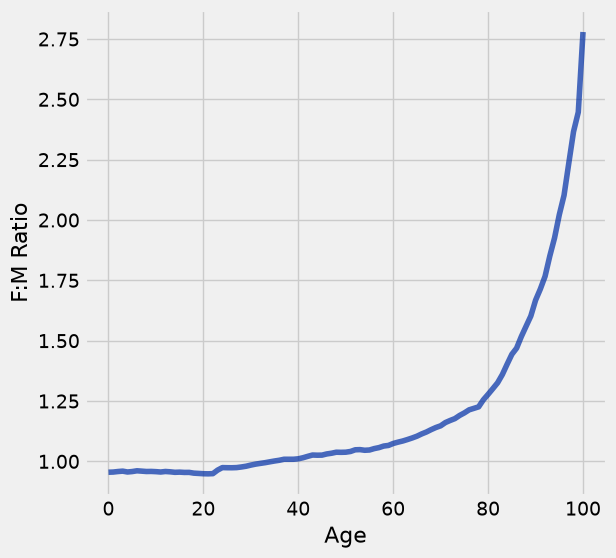

In [50]:
# datascience
ratios.plot('Age', 'F:M Ratio')


In [51]:
# polars
# hvplot
ratios_pl.hvplot.line(x='Age', y='F:M Ratio')


:Curve   [Age]   (F:M Ratio)